<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>


---
# <u> **Project Description:**</u>

The aim of this study is to perform a multi-site mega/meta analysis to asses the effects of substance use on volumetric changes in cerebellar regions (and far beyond). 

## **Hypothesis to test**

**Variables to consider:** 
  - Age
  - Sex
  - Polysubstance use : Smoke and alcohol
  
  
  **Analysis:**
   1. Volume comparisons between-groups of:
   - cerebellum regions

2. Main effects: Acapulco atlas
- Cerebellar volume ~ any drug
- Cerebellar volume ~ drug type

3. Interaction effects: Cerebellum volume
- group * sex
- group + age + sex

4. Partial Least Square: Cerebral - cerebellar association
- MDTB atlas

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings

1 
1

In [2]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

## Load Packages

In [3]:
# Load required packages  
  pacman::p_load(tidyverse,sparklyr,magrittr,lubridate,standardize,reshape2,broom,colorspace,tableone,ggridges,
    PTCA4CATA,corrplot,viridis,TExPosition,broom,ggpubr,ggdist,ggseg,data4PCCAR,foreach,doParallel,patchwork)

## Set settings for plotting

In [4]:
theme_output  <- theme(text = element_text(family = "Times New Roman"),
                        axis.text.x = element_text(size = 20),
                        axis.text.y = element_text(size = 20),
                        axis.title.x = element_text(size = 25),
                        axis.title.y = element_text(size = 25),
                        legend.text = element_text(size = 22), legend.title = element_text(size = 24),
                        title = element_text(size = 20,face = "italic"))

pal_sex <- c(alpha("#8E5A9C",1),alpha("#2879BC",1))
pal_user <- c(alpha("#757575",1),alpha("#059DC7",1))
pal_substances <- c("HC" = alpha("#757575",1), "ALC" = alpha("#C93F4D",1), 
    "ATS" = alpha("#EB8F33",1), "CANN" = alpha("#0B8755",1), 
    "COC" = alpha("#3A5589",1), "NIC" = alpha("#764EA1",1),
    "OPI" = alpha("#06AED5",1))

size_colors <- colorRampPalette(c("#19799F","#ffffff","#DE5916"),space = "rgb")(25)
common_gradient_scale <- scale_fill_gradientn(colours = size_colors, na.value = "#E7E7E7")

In [5]:
`%notin%` <- Negate(`%in%`)

## Load Rdata

In [6]:
load("Data/RData/Volumes_Cerebellum.RData")

# **1 Brain-Cerebellum association (PLS): MDTB - DK**

In [7]:
# Select only the columns that contain the volume of the cerebellum and cerebrum
MDTB_volumes <- Volumes_Cerebellum_MDTB_Harmonized %>% 
                filter(Substance != "OPI") %>% select(ID_MRI, Substance, contains("region"))
DK_volumes <- Volumes_Cerebral_DK_Harmonized %>% 
                filter(Substance != "OPI") %>% select(ID_MRI, Substance, contains("_")) 

In [8]:
boot_perm=1000
nIter=1000
split_tt=100

## **1.1 Preparation**

In [9]:
substances <- unique(Volumes_Cerebellum_MDTB_Harmonized %>% 
                filter(Substance != "OPI") %>% select(Substance))

In [10]:
#Merge both databases to match the same amount of subjects
merged_MDTB_DK_volumes <- MDTB_volumes %>% left_join(DK_volumes) %>% drop_na() %>% 
    mutate(ID_MRI = factor(ID_MRI),
    group = if_else(Substance == "HC",0,1) %>%
        factor(labels = c("HC","User")),
    Substance = factor(Substance, levels = c("HC","ALC", "ATS", "CANN", "COC", "NIC","OPI"))) %>% 
    unique() %>%
    filter(!is.na(Substance)) %>% 
    filter(complete.cases(.))

Joining with `by = join_by(ID_MRI, Substance)`


In [11]:
MDTB_volumes_only <- merged_MDTB_DK_volumes %>% select(contains("region")) 
DK_volumes_only <- merged_MDTB_DK_volumes %>% select(contains("h_"))

## **1.2 Correlation and SVD decomposition**

### **1.2.1 Correlation between metrics**

In [12]:
##getting the z-scores
MDTB_volumes_only_z <- merged_MDTB_DK_volumes %>% select(contains("region")) %>% 
    scale(center = TRUE, scale = TRUE) 
DK_volumes_only_z <- merged_MDTB_DK_volumes %>% select(contains("h_")) %>% 
    scale(center = TRUE, scale = TRUE)

###preparing the Spearman correlation matrices
MDTB_volumes_only_z_cor <- cor(MDTB_volumes_only_z, method = "pearson")

DK_volumes_only_z_cor <- cor(DK_volumes_only_z, method = "pearson")

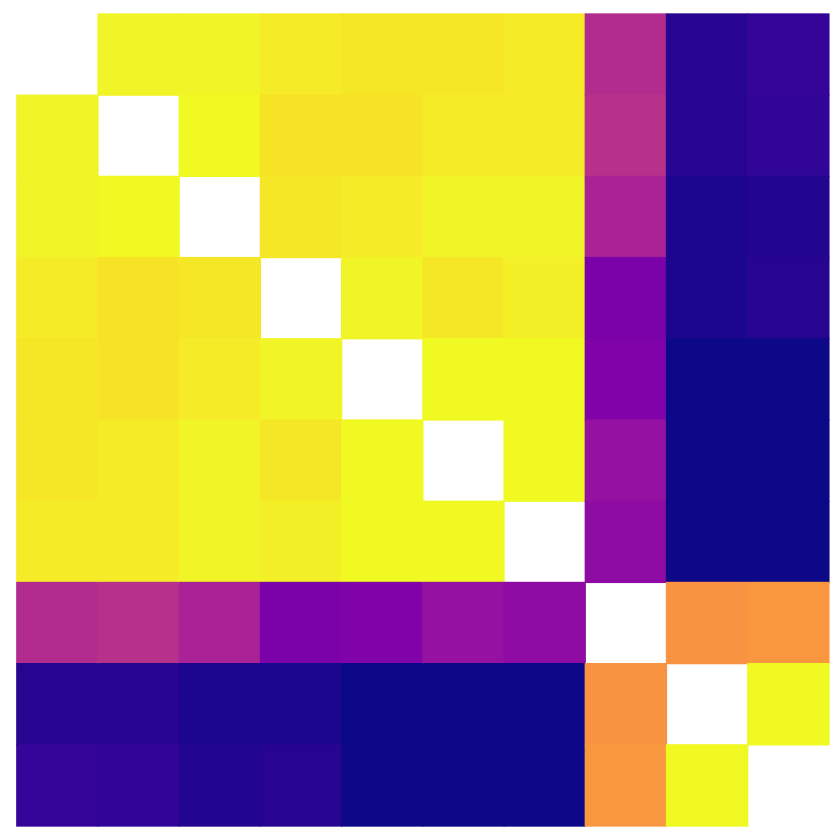

In [13]:
MDTB_volumes_only_z_cor %>%
    cor() %>%
    corrplot(method = 'color', 
            tl.col = "black",
            tl.cex = 0.7,
            tl.srt = 60,
            diag = F,
            tl.pos = "n",
            is.corr = T,
            order = "hclust", 
            hclust.method = "ward.D",
            col = plasma(100),
            cl.pos = "n")

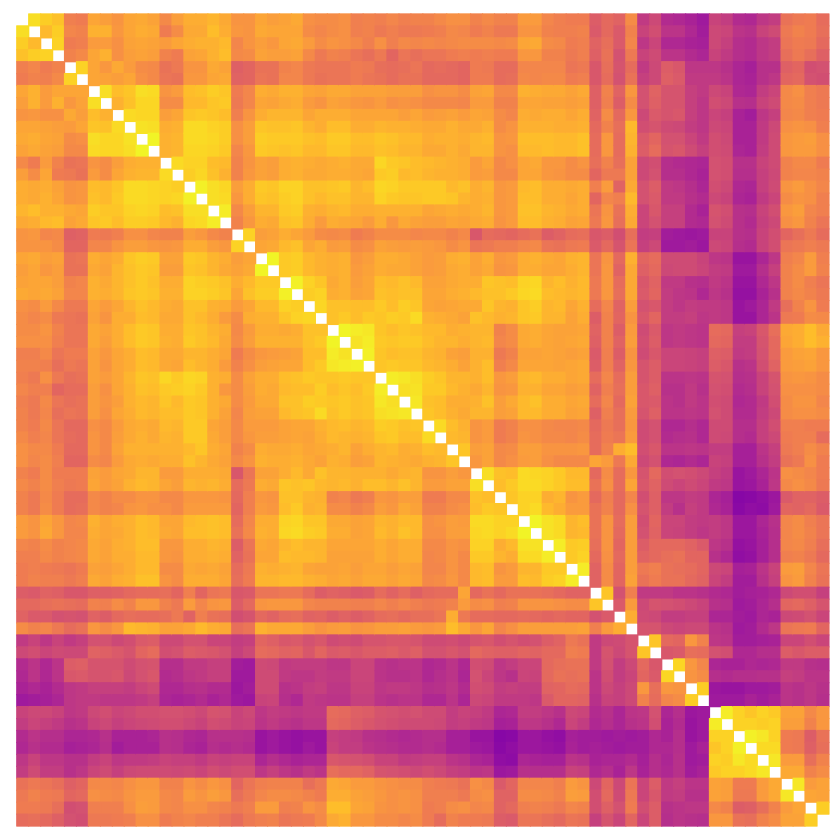

In [14]:
DK_volumes_only_z_cor %>%
    cor() %>%
    corrplot(method = 'color', 
            tl.col = "black",
            tl.cex = 0.7,
            tl.srt = 60,
            diag = F,
            tl.pos = "n",
            is.corr = T,
            order = "hclust", 
            hclust.method = "ward.D",
            col = plasma(100),
            cl.pos = "n")

### **1.2.2 Singular Value Decomposition (SVD)**

In [15]:
#Rxy matrices
MDTB_DK_Rxy <- cor(MDTB_volumes_only_z, DK_volumes_only_z, method = "spearman")

#Omega matrices
MDTB_DK_omega <- t(solve(chol(MDTB_volumes_only_z_cor))) %*% MDTB_DK_Rxy %*% solve(chol(DK_volumes_only_z_cor))

##getting the variance explained of each singular value
MDTB_DK_PLS_svd_scaled <- svd(MDTB_DK_Rxy)

MDTB_DK_PLS_variance <- MDTB_DK_PLS_svd_scaled$d^2/sum(MDTB_DK_PLS_svd_scaled$d^2)

In [16]:
#Standardizing the V singular values by the singular values
MDTB_DK_S_diag_PLS <- as.data.frame(diag(MDTB_DK_PLS_svd_scaled$d))
MDTB_DK_S_diag_PLS <- as.matrix(MDTB_DK_S_diag_PLS)
MDTB_DK_V_S_PLS <- MDTB_DK_PLS_svd_scaled$v %*% MDTB_DK_S_diag_PLS

#projecting the standardized V singular values by the residualized and normalized brain matrix 
MDTB_DK_V_Ymat_PLS <- DK_volumes_only_z %*% MDTB_DK_V_S_PLS
MDTB_DK_V_Ymat_PLS <- as.data.frame(MDTB_DK_V_Ymat_PLS)

#Standardizing the U singular values by the singular values
MDTB_DK_U_S_PLS <- MDTB_DK_PLS_svd_scaled$u %*% MDTB_DK_S_diag_PLS

#projecting the standardized U singular values by the residualized and normalized behaviour matrix
MDTB_DK_U_Xmat_PLS <- MDTB_volumes_only_z %*% MDTB_DK_U_S_PLS
MDTB_DK_U_Xmat_PLS <- as.data.frame(MDTB_DK_U_Xmat_PLS)

In [17]:
MDTB_DK_latentScores_list_PLS <- lapply(1:10, function(i) tibble(U = MDTB_DK_U_Xmat_PLS[, i], V = MDTB_DK_V_Ymat_PLS[, i])) %>% 
    set_names(paste0("LV_", 1:10))

## **1.3 Running PLS**

### **1.3.1 Permutation**

In [18]:
set.seed(42)
PLS_permutation <- function(X, Y) {

    resamplesX <- sample(nrow(X), replace = FALSE)
    resampled_X <- scale(X[resamplesX, ], center = TRUE, scale = TRUE)
    resampled_Y <- scale(Y, center = TRUE, scale = TRUE)

    resamples_Rxy <- cor(resampled_X, resampled_Y, method = "spearman")
    resamples_PLS_svd_scaled <- svd(resamples_Rxy)
    resamples_singular_values <- resamples_PLS_svd_scaled$d

    sum_of_squares <- sapply(seq_along(resamples_singular_values), function(idx) {
        sum(resamples_singular_values[idx:length(resamples_singular_values)]^2)
    })

    setNames(as.list(sum_of_squares), paste0("sum_of_squares", seq_along(sum_of_squares)))
}

In [19]:
n_workers <- max(1L, parallel::detectCores(logical = FALSE) - 1L)

if (!file.exists("Data/RData/PLS_permutation_MDTB.RData")) {
    cl <- parallel::makeCluster(n_workers)
    doParallel::registerDoParallel(cl)

    PLS_permutation_output <- foreach(
        i = seq_len(split_tt),
        .packages = "stats"
    ) %dopar% {
        PLS_permutation(MDTB_volumes_only, DK_volumes_only)
    }

    save(PLS_permutation_output, file = "Data/RData/PLS_permutation_MDTB.RData")
    parallel::stopCluster(cl)
} else {
    load("Data/RData/PLS_permutation_MDTB.RData")
}

In [20]:
#### getting the sum of squares for each LV
MDTB_DK_singVal <- as.data.frame(MDTB_DK_PLS_svd_scaled$d)

####1 THROUGH 28
MDTB_DK_singVal_squared <- as.data.frame(apply(MDTB_DK_singVal, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed1 <- sum(MDTB_DK_singVal_squared)

MDTB_DK_singVal2_10 <- as.data.frame(MDTB_DK_singVal[-c(1),])
MDTB_DK_singVal_squared2_10 <- as.data.frame(apply(MDTB_DK_singVal2_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed2 <- sum(MDTB_DK_singVal_squared2_10)

MDTB_DK_singVal3_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2),])
MDTB_DK_singVal_squared3_10 <- as.data.frame(apply(MDTB_DK_singVal3_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed3 <- sum(MDTB_DK_singVal_squared3_10)

MDTB_DK_singVal4_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3),])
MDTB_DK_singVal_squared4_10 <- as.data.frame(apply(MDTB_DK_singVal4_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed4 <- sum(MDTB_DK_singVal_squared4_10)

MDTB_DK_singVal5_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4),])
MDTB_DK_singVal_squared5_10 <- as.data.frame(apply(MDTB_DK_singVal5_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed5 <- sum(MDTB_DK_singVal_squared5_10)

MDTB_DK_singVal6_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4,5),])
MDTB_DK_singVal_squared6_10 <- as.data.frame(apply(MDTB_DK_singVal6_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed6 <- sum(MDTB_DK_singVal_squared6_10)

MDTB_DK_singVal7_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4,5,6),])
MDTB_DK_singVal_squared7_10 <- as.data.frame(apply(MDTB_DK_singVal7_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed7 <- sum(MDTB_DK_singVal_squared7_10)

MDTB_DK_singVal8_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4,5,6,7),])
MDTB_DK_singVal_squared8_10 <- as.data.frame(apply(MDTB_DK_singVal8_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed8 <- sum(MDTB_DK_singVal_squared8_10)

MDTB_DK_singVal9_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4,5,6,7,8),])
MDTB_DK_singVal_squared9_10 <- as.data.frame(apply(MDTB_DK_singVal9_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed9 <- sum(MDTB_DK_singVal_squared9_10)

MDTB_DK_singVal10_10 <- as.data.frame(MDTB_DK_singVal[-c(1,2,3,4,5,6,7,8,9),])
MDTB_DK_singVal_squared10_10 <- as.data.frame(apply(MDTB_DK_singVal10_10, 1, function(x) x^2))
MDTB_DK_singVal_squared_summed10 <- sum(MDTB_DK_singVal_squared10_10)

In [21]:
#### Creating data frames of the sum of square singular values 
permutation_iterations <- seq_len(length(PLS_permutation_output))

MDTB_DK_singVal1_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares1))
MDTB_DK_singVal1_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal1_permutation_results))

MDTB_DK_singVal2_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares2))
MDTB_DK_singVal2_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal2_permutation_results))

MDTB_DK_singVal3_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares3))
MDTB_DK_singVal3_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal3_permutation_results))

MDTB_DK_singVal4_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares4))
MDTB_DK_singVal4_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal4_permutation_results))

MDTB_DK_singVal5_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares5))
MDTB_DK_singVal5_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal5_permutation_results))

MDTB_DK_singVal6_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares6))
MDTB_DK_singVal6_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal6_permutation_results))

MDTB_DK_singVal7_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares7))
MDTB_DK_singVal7_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal7_permutation_results))

MDTB_DK_singVal8_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares8))
MDTB_DK_singVal8_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal8_permutation_results))

MDTB_DK_singVal9_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares9))
MDTB_DK_singVal9_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal9_permutation_results))

MDTB_DK_singVal10_permutation_results <- sapply(permutation_iterations, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares10))
MDTB_DK_singVal10_permutation_results <- as.data.frame(as.vector(MDTB_DK_singVal10_permutation_results))

In [22]:
#### getting the p-value 
MDTB_DK_pval_singVal1 <- filter(MDTB_DK_singVal1_permutation_results, MDTB_DK_singVal1_permutation_results >= MDTB_DK_singVal_squared_summed1)
MDTB_DK_pval_singVal2 <- filter(MDTB_DK_singVal2_permutation_results, MDTB_DK_singVal2_permutation_results >= MDTB_DK_singVal_squared_summed2)
MDTB_DK_pval_singVal3 <- filter(MDTB_DK_singVal3_permutation_results, MDTB_DK_singVal3_permutation_results >= MDTB_DK_singVal_squared_summed3)
MDTB_DK_pval_singVal4 <- filter(MDTB_DK_singVal4_permutation_results, MDTB_DK_singVal4_permutation_results >= MDTB_DK_singVal_squared_summed4)
MDTB_DK_pval_singVal5 <- filter(MDTB_DK_singVal5_permutation_results, MDTB_DK_singVal5_permutation_results >= MDTB_DK_singVal_squared_summed5)
MDTB_DK_pval_singVal6 <- filter(MDTB_DK_singVal6_permutation_results, MDTB_DK_singVal6_permutation_results >= MDTB_DK_singVal_squared_summed6)
MDTB_DK_pval_singVal7 <- filter(MDTB_DK_singVal7_permutation_results, MDTB_DK_singVal7_permutation_results >= MDTB_DK_singVal_squared_summed7)
MDTB_DK_pval_singVal8 <- filter(MDTB_DK_singVal8_permutation_results, MDTB_DK_singVal8_permutation_results >= MDTB_DK_singVal_squared_summed8)
MDTB_DK_pval_singVal9 <- filter(MDTB_DK_singVal9_permutation_results, MDTB_DK_singVal9_permutation_results >= MDTB_DK_singVal_squared_summed9)
MDTB_DK_pval_singVal10 <- filter(MDTB_DK_singVal10_permutation_results, MDTB_DK_singVal10_permutation_results >= MDTB_DK_singVal_squared_summed10)

### **1.3.2 Bootstrap**

In [23]:
bootstrap_resampling_PLS_SingularVectors <- function(X, Y, nsub) {

    Xrow <- nrow(X)
    sample_idx <- sample(Xrow, nsub, replace = TRUE)

    resampled_X <- scale(X[sample_idx, ], center = TRUE, scale = TRUE)
    resampled_Y <- scale(Y[sample_idx, ], center = TRUE, scale = TRUE)

    resamples_Rxy <- cor(resampled_X, resampled_Y, method = "spearman")
    resamples_PLS_svd_scaled <- svd(resamples_Rxy)

    list("U_mat" = resamples_PLS_svd_scaled$u, "V_mat" = resamples_PLS_svd_scaled$v)
}

In [24]:
n_workers <- max(1L, parallel::detectCores(logical = FALSE) - 1L)

if (!file.exists("Data/RData/PLS_bootstrap_singvectors_MDTB.RData")) {
    cl <- parallel::makeCluster(n_workers)
    doParallel::registerDoParallel(cl)

    bootstrap_results <- foreach(
        i = seq_len(boot_perm),
        .packages = "stats"
    ) %dopar% {
        bootstrap_resampling_PLS_SingularVectors(
            MDTB_volumes_only,
            DK_volumes_only,
            nrow(MDTB_volumes_only)
        )
    }

    bootstrap_PLS_singvectors <- list(
        U_mat = lapply(bootstrap_results, `[[`, "U_mat"),
        V_mat = lapply(bootstrap_results, `[[`, "V_mat")
    )

    save(bootstrap_PLS_singvectors, file = "Data/RData/PLS_bootstrap_singvectors_MDTB.RData")
    parallel::stopCluster(cl)
} else {
    load("Data/RData/PLS_bootstrap_singvectors_MDTB.RData")
}

### **1.3.3 Split-Half**

In [25]:
set.seed(42)
PLS_splithalf <- function(X, Y) {

    split_half1 <- sort(sample(nrow(X), floor(nrow(X) / 2), replace = FALSE))
    split_half2 <- setdiff(seq_len(nrow(X)), split_half1)

    new_sampleX1 <- scale(X[split_half1, ], center = TRUE, scale = TRUE)
    new_sampleY1 <- scale(Y[split_half1, ], center = TRUE, scale = TRUE)
    new_sampleX2 <- scale(X[split_half2, ], center = TRUE, scale = TRUE)
    new_sampleY2 <- scale(Y[split_half2, ], center = TRUE, scale = TRUE)

    Rxy_1 <- cor(new_sampleX1, new_sampleY1, method = "spearman")
    Rxy_2 <- cor(new_sampleX2, new_sampleY2, method = "spearman")

    svd1 <- svd(Rxy_1)
    svd2 <- svd(Rxy_2)

    diagonal_LV_Y_Corr <- diag(abs(cor(svd1$v, svd2$v)))
    diagonal_LV_X_Corr <- diag(abs(cor(svd1$u, svd2$u)))

    split_half_result <- c(
        setNames(as.list(diagonal_LV_Y_Corr), paste0("SingVectors_V", seq_along(diagonal_LV_Y_Corr))),
        setNames(as.list(diagonal_LV_X_Corr), paste0("SingVectors_U", seq_along(diagonal_LV_X_Corr)))
    )

    split_half_result
}

In [26]:
n_workers <- max(1L, parallel::detectCores(logical = FALSE) - 1L)

if (!file.exists("Data/RData/PLS_splithalf_MDTB.RData")) {
    cl <- parallel::makeCluster(n_workers)
    doParallel::registerDoParallel(cl)

    PLS_splithalf_output <- foreach(
        i = seq_len(split_tt),
        .packages = "stats"
    ) %dopar% {
        PLS_splithalf(MDTB_volumes_only, DK_volumes_only)
    }

    save(PLS_splithalf_output, file = "Data/RData/PLS_splithalf_MDTB.RData")
    parallel::stopCluster(cl)
} else {
    load("Data/RData/PLS_splithalf_MDTB.RData")
}

In [27]:
####X LATENT VARIABLES
MDTB_DK_SingVecU1_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U1))
MDTB_DK_SingVecU1_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU1_splitHalf))

MDTB_DK_SingVecU2_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U2))
MDTB_DK_SingVecU2_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU2_splitHalf))

MDTB_DK_SingVecU3_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U3))
MDTB_DK_SingVecU3_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU3_splitHalf))

MDTB_DK_SingVecU4_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U4))
MDTB_DK_SingVecU4_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU4_splitHalf))

MDTB_DK_SingVecU5_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U5))
MDTB_DK_SingVecU5_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU5_splitHalf))

MDTB_DK_SingVecU6_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U6))
MDTB_DK_SingVecU6_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU6_splitHalf))

MDTB_DK_SingVecU7_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U7))
MDTB_DK_SingVecU7_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU7_splitHalf))

MDTB_DK_SingVecU8_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U8))
MDTB_DK_SingVecU8_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU8_splitHalf))

MDTB_DK_SingVecU9_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U9))
MDTB_DK_SingVecU9_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU9_splitHalf))

MDTB_DK_SingVecU10_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U10))
MDTB_DK_SingVecU10_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecU10_splitHalf))


In [28]:
MDTB_DK_SingVecU_splitHalf <- cbind.data.frame(MDTB_DK_SingVecU1_splitHalf, MDTB_DK_SingVecU2_splitHalf, MDTB_DK_SingVecU3_splitHalf,
    MDTB_DK_SingVecU4_splitHalf, MDTB_DK_SingVecU5_splitHalf, MDTB_DK_SingVecU6_splitHalf, MDTB_DK_SingVecU7_splitHalf,
    MDTB_DK_SingVecU8_splitHalf, MDTB_DK_SingVecU9_splitHalf, MDTB_DK_SingVecU10_splitHalf)

In [29]:
##Y VARIABLES
MDTB_DK_SingVecV1_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V1))
MDTB_DK_SingVecV1_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV1_splitHalf))

MDTB_DK_SingVecV2_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V2))
MDTB_DK_SingVecV2_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV2_splitHalf))

MDTB_DK_SingVecV3_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V3))
MDTB_DK_SingVecV3_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV3_splitHalf))

MDTB_DK_SingVecV4_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V4))
MDTB_DK_SingVecV4_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV4_splitHalf))

MDTB_DK_SingVecV5_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V5))
MDTB_DK_SingVecV5_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV5_splitHalf))

MDTB_DK_SingVecV6_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V6))
MDTB_DK_SingVecV6_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV6_splitHalf))

MDTB_DK_SingVecV7_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V7))
MDTB_DK_SingVecV7_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV7_splitHalf))

MDTB_DK_SingVecV8_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V8))
MDTB_DK_SingVecV8_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV8_splitHalf))

MDTB_DK_SingVecV9_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V9))
MDTB_DK_SingVecV9_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV9_splitHalf))

MDTB_DK_SingVecV10_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V10))
MDTB_DK_SingVecV10_splitHalf <- as.data.frame(as.vector(MDTB_DK_SingVecV10_splitHalf))


In [30]:
MDTB_DK_SingVecV_splitHalf <- cbind.data.frame(MDTB_DK_SingVecV1_splitHalf,MDTB_DK_SingVecV2_splitHalf,MDTB_DK_SingVecV3_splitHalf,
    MDTB_DK_SingVecV4_splitHalf,MDTB_DK_SingVecV5_splitHalf,MDTB_DK_SingVecV6_splitHalf,MDTB_DK_SingVecV7_splitHalf,
    MDTB_DK_SingVecV8_splitHalf,MDTB_DK_SingVecV9_splitHalf,MDTB_DK_SingVecV10_splitHalf)

### **1.3.4 Train-test**

In [31]:
set.seed(42)
PLS_train_test <- function(X, Y) {

    train <- sort(sample(nrow(X), round(0.8 * nrow(X)), replace = FALSE))
    test <- setdiff(seq_len(nrow(X)), train)

    training_X1 <- scale(X[train, ], center = TRUE, scale = TRUE)
    training_Y1 <- scale(Y[train, ], center = TRUE, scale = TRUE)
    testing_X2 <- scale(X[test, ], center = TRUE, scale = TRUE)
    testing_Y2 <- scale(Y[test, ], center = TRUE, scale = TRUE)

    Rxy_train <- cor(training_Y1, training_X1, method = "spearman")
    svd_Rxy <- svd(Rxy_train)

    Rxy_test <- cor(testing_Y2, testing_X2, method = "spearman")
    sing_val_test_prediction <- diag(abs(t(svd_Rxy$u) %*% Rxy_test %*% svd_Rxy$v))

    setNames(as.list(sing_val_test_prediction), paste0("SV", seq_along(sing_val_test_prediction), "_test_pred"))
}

In [32]:
n_workers <- max(1L, parallel::detectCores(logical = FALSE) - 1L)

if (!file.exists("Data/RData/PLS_testTrain_MDTB.RData")) {
    cl <- parallel::makeCluster(n_workers)
    doParallel::registerDoParallel(cl)

    PLS_testTrain_output <- foreach(
        i = seq_len(split_tt),
        .packages = "stats"
    ) %dopar% {
        PLS_train_test(MDTB_volumes_only, DK_volumes_only)
    }

    save(PLS_testTrain_output, file = "Data/RData/PLS_testTrain_MDTB.RData")
    parallel::stopCluster(cl)
} else {
    load("Data/RData/PLS_testTrain_MDTB.RData")
}

In [33]:
#### Extracting predicted singular values
####X LATENT VARIABLES
MDTB_DK_singVal1_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV1_test_pred))
MDTB_DK_singVal1_trainTest <- as.vector(MDTB_DK_singVal1_trainTest)

MDTB_DK_singVal2_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV2_test_pred))
MDTB_DK_singVal2_trainTest <- as.vector(MDTB_DK_singVal2_trainTest)

MDTB_DK_singVal3_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV3_test_pred))
MDTB_DK_singVal3_trainTest <- as.vector(MDTB_DK_singVal3_trainTest)

MDTB_DK_singVal4_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV4_test_pred))
MDTB_DK_singVal4_trainTest <- as.vector(MDTB_DK_singVal4_trainTest)

MDTB_DK_singVal5_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV5_test_pred))
MDTB_DK_singVal5_trainTest <- as.vector(MDTB_DK_singVal5_trainTest)

MDTB_DK_singVal6_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV6_test_pred))
MDTB_DK_singVal6_trainTest <- as.vector(MDTB_DK_singVal6_trainTest)

MDTB_DK_singVal7_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV7_test_pred))
MDTB_DK_singVal7_trainTest <- as.vector(MDTB_DK_singVal7_trainTest)

MDTB_DK_singVal8_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV8_test_pred))
MDTB_DK_singVal8_trainTest <- as.vector(MDTB_DK_singVal8_trainTest)

MDTB_DK_singVal9_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV9_test_pred))
MDTB_DK_singVal9_trainTest <- as.vector(MDTB_DK_singVal9_trainTest)

MDTB_DK_singVal10_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV10_test_pred))
MDTB_DK_singVal10_trainTest <- as.vector(MDTB_DK_singVal10_trainTest)


In [34]:
MDTB_DK_singVal_trainTest <- cbind.data.frame(MDTB_DK_singVal1_trainTest, MDTB_DK_singVal2_trainTest, MDTB_DK_singVal3_trainTest, 
    MDTB_DK_singVal4_trainTest, MDTB_DK_singVal5_trainTest, MDTB_DK_singVal6_trainTest, MDTB_DK_singVal7_trainTest,
    MDTB_DK_singVal8_trainTest, MDTB_DK_singVal9_trainTest, MDTB_DK_singVal10_trainTest)

## **1.4 Processing results**

### Some variables

In [35]:
MDTB_names <- MDTB_volumes_only_z %>% colnames()
DK_names <- DK_volumes_only_z %>% colnames()

### **1.4.1 Permutation**

In [36]:
# getting the sum of squares for each LV
MDTB_DK_pval_singVal_list <- list(MDTB_DK_pval_singVal1, MDTB_DK_pval_singVal2, MDTB_DK_pval_singVal3, MDTB_DK_pval_singVal4, MDTB_DK_pval_singVal5, 
    MDTB_DK_pval_singVal6, MDTB_DK_pval_singVal7, MDTB_DK_pval_singVal8, MDTB_DK_pval_singVal9, MDTB_DK_pval_singVal10) %>% set_names(paste0("LV_", 1:10))

### **1.4.2 Bootstraping**

In [37]:
#######      2. GETTING CONFIDENCE INTERVALS
##getting the values 
SingVect_UMat_full <- function(X, numboot, LV) {
    X <- X
    numboot <- numboot
    
    SingVect_Umat_PLS <- vector("list", numboot)
    
    for(idx in 1:10) {
        SingVect_Umat_PLS[[idx]] <- sapply(1:numboot, function(i) unlist(X[[i]][idx,LV]))
    }
    return(SingVect_Umat_PLS)
}

SingVect_VMat_full <- function(X, numboot, LV) {
  
  X <- X
  numboot <- numboot
  
  SingVect_BehCog_Vmat_PLS <- vector("list", numboot)
  
  for(idx in 1:68) {
    SingVect_BehCog_Vmat_PLS[[idx]] <- sapply(1:numboot, function(i) unlist(X[[i]][idx,LV]))
  }
  return(SingVect_BehCog_Vmat_PLS)
}

In [38]:
SingVect_Umat_PLS_list <- 1:10 %>% map(~ SingVect_UMat_full(bootstrap_PLS_singvectors$U_mat, boot_perm,.x) ) %>% 
    set_names(paste0("LV_", 1:10))

####### getting the confidence intervals 
SingVect_Umat_PLS_CI_full <- 1:10 %>% map(~ sapply(1:10, function(i) unlist(SingVect_Umat_PLS_list[[.x]][[i]])) %>% 
    as.data.frame() ) %>% set_names(paste0("LV_", 1:10))

SingVect_Umat_PLS_CIval_full <- SingVect_Umat_PLS_CI_full %>% map(~ as.data.frame(apply(.x, 2, 
        function(x) quantile(x, c(.05, .95)))) %>% 
    t() %>% as_tibble() %>% add_column(Region = MDTB_names ,.before = 1))

In [39]:
SingVect_Vmat_PLS_list <- 1:10 %>% map(~ SingVect_VMat_full(bootstrap_PLS_singvectors$V_mat, boot_perm,.x) ) %>% 
    set_names(paste0("LV_", 1:10))

####### getting the confidence intervals 
SingVect_Vmat_PLS_CI_full <- 1:10 %>% map(~ sapply(1:68, function(i) unlist(SingVect_Vmat_PLS_list[[.x]][[i]])) %>% 
    as.data.frame() ) %>% set_names(paste0("LV_", 1:10))

SingVect_Vmat_PLS_CIval_full <- SingVect_Vmat_PLS_CI_full %>% map(~ as.data.frame(apply(.x, 2, 
        function(x) quantile(x, c(.05, .95)))) %>% 
    t() %>% as_tibble() %>% add_column(Region = DK_names ,.before = 1))

### **1.4.3 Split-half**

In [40]:
#### Calculating reproducibility
###################################

###calculating the z-score for the correlations of singular vectors across the split-half iterations 

SingVecU_splitHalf_z <- apply(MDTB_DK_SingVecU_splitHalf, 2, function(x) (mean(x)) / sd(x))
SingVecV_splitHalf_z <- apply(MDTB_DK_SingVecV_splitHalf, 2, function(x) (mean(x)) / sd(x))

## calculating the mean of the distributions 
SingVecU_splitHalf_mean <- apply(MDTB_DK_SingVecU_splitHalf, 2, function(x) (mean(x)))
SingVecV_splitHalf_mean <- apply(MDTB_DK_SingVecV_splitHalf, 2, function(x) (mean(x)))

### **1.4.4 Train-test**

In [41]:
SingVal_trainTest_z <- apply(MDTB_DK_singVal_trainTest, 2, scale)

## **2 Figures**

### **2.1 Permutation (p-values)**

In [42]:
permutation_alpha_cutoff <- 0.05 * nrow(MDTB_DK_singVal1_permutation_results)

MDTB_DK_pval_singVal_list_filtered <- MDTB_DK_pval_singVal_list %>% 
    map(~ filter(.x, n() <= permutation_alpha_cutoff)) %>% 
    discard(~ nrow(.x) == 0)

### **2.2 Bootstrap (significant LV)**

In [43]:
##getting the PLS figures 
MDTB_DK_PLS.u <- MDTB_DK_PLS_svd_scaled$u %>% 
    set_rownames(MDTB_volumes_only_z %>% colnames()) %>% 
    set_colnames(paste0("LV_", 1:10)) %>% 
    as.data.frame() %>% 
    rownames_to_column(var = "Region") %>%
    mutate(Region = str_replace_all(Region, "region_", "Region ")) %>%
    mutate(Region = factor(Region, levels = c(paste0("Region ", 1:10))))

MDTB_DK_PLS.v <- MDTB_DK_PLS_svd_scaled$v %>% 
    set_rownames(DK_volumes_only_z %>% colnames()) %>% 
    set_colnames(paste0("LV_", 1:10)) %>% 
    as.data.frame() %>% 
    rownames_to_column(var = "Region") %>%
    mutate(Region = str_replace_all(Region, "_volume", ""))


In [44]:
MDTB_DK_LV_CI.u <- SingVect_Umat_PLS_CIval_full %>% names() %>% 
    map(~ SingVect_Umat_PLS_CIval_full[[.x]] %>%  
        rename(CI_5 = "5%") %>%
        rename(CI_95 = "95%") %>%
        add_column(LV = MDTB_DK_PLS.u[[.x]], .before = 2) %>%
    mutate(Region = str_replace_all(Region, "region_", "Region "))  %>%
    mutate(Region = factor(Region, levels = c(paste0("Region ", 1:10))) )) %>%
    set_names(SingVect_Umat_PLS_CIval_full %>% names())

MDTB_DK_LV_CI.v <- SingVect_Vmat_PLS_CIval_full %>% names() %>% 
    map(~ SingVect_Vmat_PLS_CIval_full[[.x]] %>%  
        rename(CI_5 = "5%") %>%
        rename(CI_95 = "95%") %>%
        add_column(LV = MDTB_DK_PLS.v[[.x]], .before = 2) %>%
    mutate(Region = str_replace_all(Region, "_volume", "")) ) %>%
    set_names(SingVect_Vmat_PLS_CIval_full %>% names())

In [45]:
plot_MDTB_DK_LV_CI.u_bar <- MDTB_DK_LV_CI.u %>% names()  %>%
        map(~
        ggplot(MDTB_DK_LV_CI.u[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV, fill = LV)) +
        geom_bar(stat = "identity",
                                        show.legend = FALSE,   
                                        color = "black") +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = LV - CI_5, ymax = LV - CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        common_gradient_scale +  
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(MDTB_DK_LV_CI.u %>% names())

plot_MDTB_DK_LV_CI.v_bar <- MDTB_DK_LV_CI.v %>% names()  %>%
        map(~
        ggplot(MDTB_DK_LV_CI.v[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV, fill = LV)) +
        geom_bar(stat = "identity",
                                        show.legend = FALSE,   
                                        color = "black") +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = LV - CI_5, ymax = LV - CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        common_gradient_scale +  
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(MDTB_DK_LV_CI.v %>% names())


In [46]:
plot_MDTB_DK_LV_CI.u_dot <- MDTB_DK_LV_CI.u %>% names() %>%
        map(~
        ggplot(MDTB_DK_LV_CI.u[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV)) +
        geom_point(aes(color = ifelse(LV > (CI_95) | LV < (CI_5), "skyblue4", "#CF4D6F")), size = 3) +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = CI_5, ymax = CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        scale_color_manual(values = c("skyblue4", "#CF4D6F")) +
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                legend.position = "none",
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(MDTB_DK_LV_CI.u %>% names())

plot_MDTB_DK_LV_CI.v_dot <- MDTB_DK_LV_CI.v %>% names() %>%
        map(~
        ggplot(MDTB_DK_LV_CI.v[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV)) +
        geom_point(aes(color = ifelse(LV > (CI_95) | LV < (CI_5), "skyblue4", "#CF4D6F")), size = 3) +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = CI_5, ymax = CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        scale_color_manual(values = c("skyblue4", "#CF4D6F")) +
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                legend.position = "none",
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(MDTB_DK_LV_CI.v %>% names())


### **2.3 Train-test**

In [47]:
plot_MDTB_DK_trainTest <- MDTB_DK_singVal_trainTest %>% melt() %>%
  mutate(variable = str_replace_all(variable, "MDTB_DK_", "")) %>%
  mutate(variable = str_replace_all(variable, "_trainTest", "")) %>%
  mutate(variable = str_replace_all(variable, "singVal", "LV")) %>% 
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS Test-set Reliability")) +
  labs(y="", x="Predicted Singular Values") + 
  theme_classic() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(MDTB_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = str_replace_all(variable, "MDTB_DK_", "")) %>% 
      mutate(variable = str_replace_all(variable, "_trainTest", "")) %>% 
      mutate(variable = str_replace_all(variable, "singVal", "LV")) %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>% 
      pull(variable)) %in% c("LV8", "LV9", "LV10"), "#CF4D6F", "black")))

No id variables; using all as measure variables

No id variables; using all as measure variables



### **2.4 Split-Half**

In [48]:
plot_MDTB_DK_SplitHalf_U <- MDTB_DK_SingVecU_splitHalf %>% 
  set_colnames(paste0("LV", 1:10)) %>% melt() %>%
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS MDTB reproducibility")) +
  labs(y="", x="Pearson r-value") + 
  theme_classic() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(MDTB_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>% 
      pull(variable)) %in% c("LV8", "LV9", "LV10"), "#CF4D6F", "black")))

plot_MDTB_DK_SplitHalf_V <- MDTB_DK_SingVecV_splitHalf %>% 
  set_colnames(paste0("LV", 1:10)) %>% melt() %>%
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS DK reproducibility")) +
  labs(y="", x="Pearson r-value") + 
  theme_classic() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(MDTB_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10)))) %>% 
      pull(variable)) %in% c("LV8", "LV9", "LV10"), "#CF4D6F", "black")))


No id variables; using all as measure variables

No id variables; using all as measure variables

No id variables; using all as measure variables

No id variables; using all as measure variables



## **3 Brain plot**

In [49]:
#ifelse(LV > (CI_95) | LV < (CI_5), LV, NA))

In [50]:
MDTB_DK_Data4brain <- MDTB_DK_LV_CI.v %>%
    imap(~ .x %>%
        transmute(
            label = Region %>%
                str_to_lower() %>%
                str_replace_all("\\.", "_"),
            LV,
            CI_5,
            CI_95
        )
    )

plot_MDTB_DK_Data4brain <- MDTB_DK_Data4brain %>%
    imap(~ {
        lv_data <- .x %>%
            filter(!is.na(label), !is.na(LV))

        ggplot(lv_data) +
            geom_brain(
                atlas = dk(),
                position = position_brain(view ~ hemi, views = c("medial", "lateral")),
                aes(fill = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA))
            ) +
            common_gradient_scale +
            labs(fill = "Brain loadings", title = .y) +
            theme_brain(text.family = "Times New Roman") +
            theme(
                axis.text.y.left = element_blank(),
                axis.text.x.bottom = element_blank(),
                legend.title.position = "right",
                legend.title = element_text(angle = 270, hjust = 0.5, size = 17),
                legend.text = element_text(size = 18),
                legend.key.height = unit(1.6, "cm"),
                legend.key.width = unit(0.5, "cm"),
                legend.key = element_rect(color = "black", linewidth = 1),
                legend.position = "right"
            )
    })

Merging atlas and data by label.
Merging atlas and data by label.


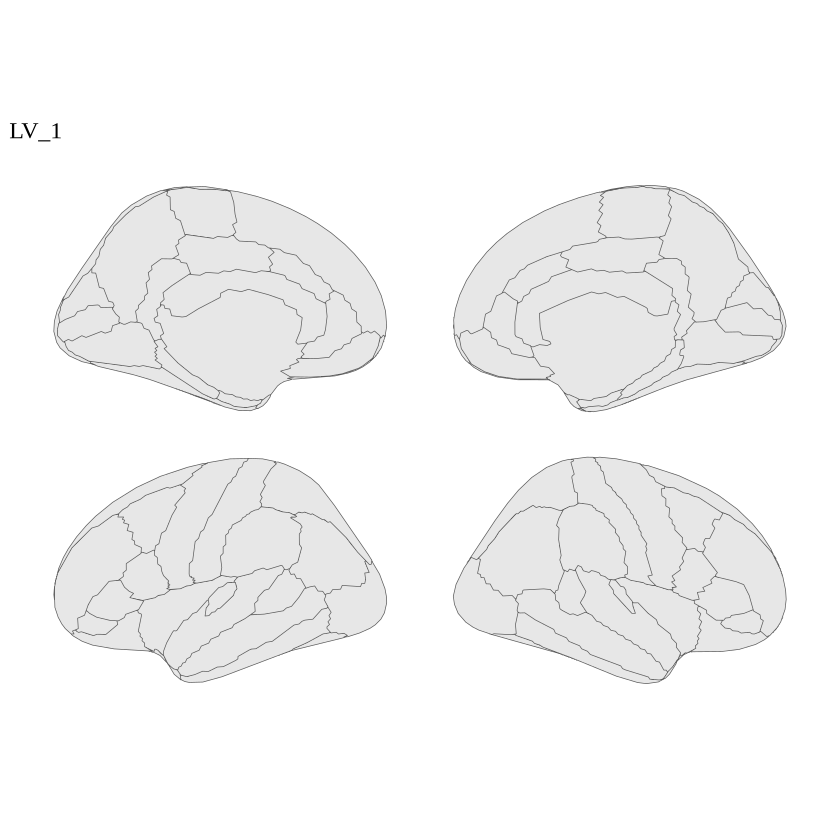

Merging atlas and data by label.


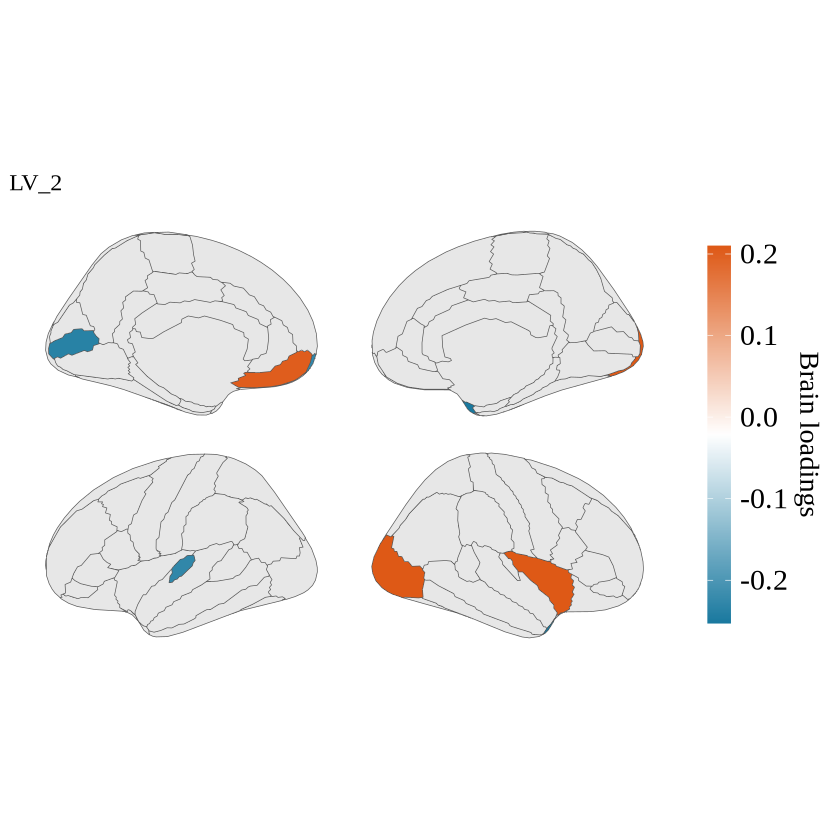

Merging atlas and data by label.


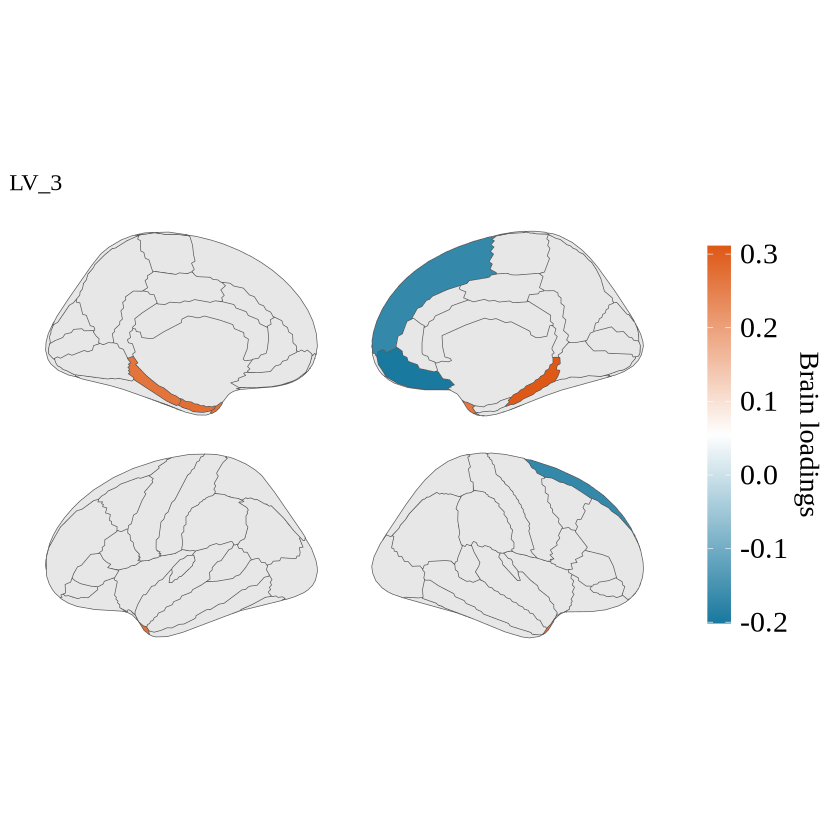

Merging atlas and data by label.


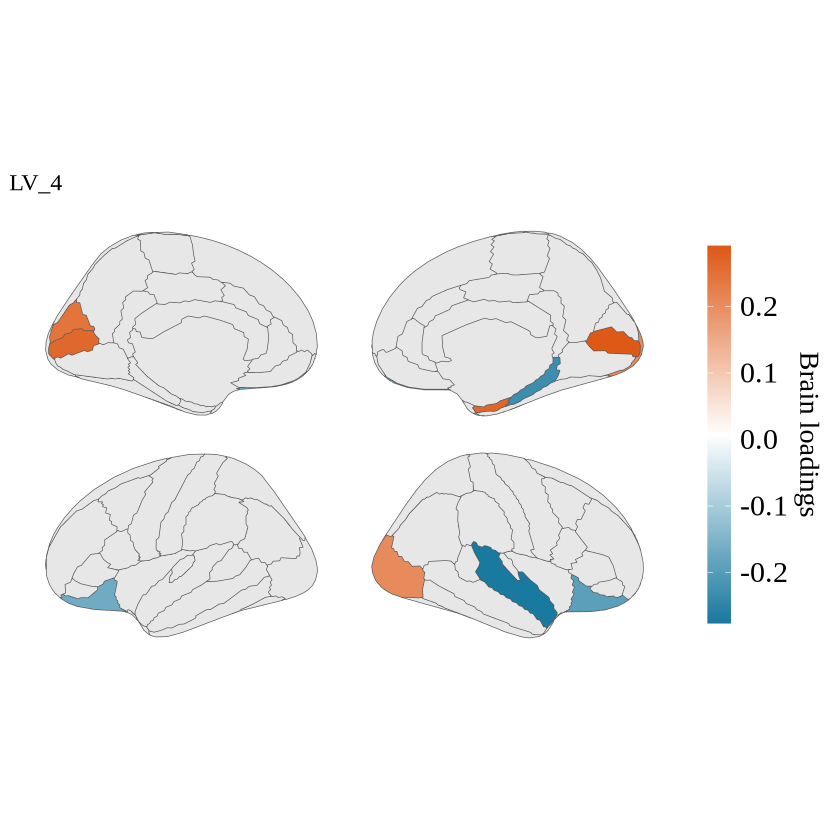

Merging atlas and data by label.


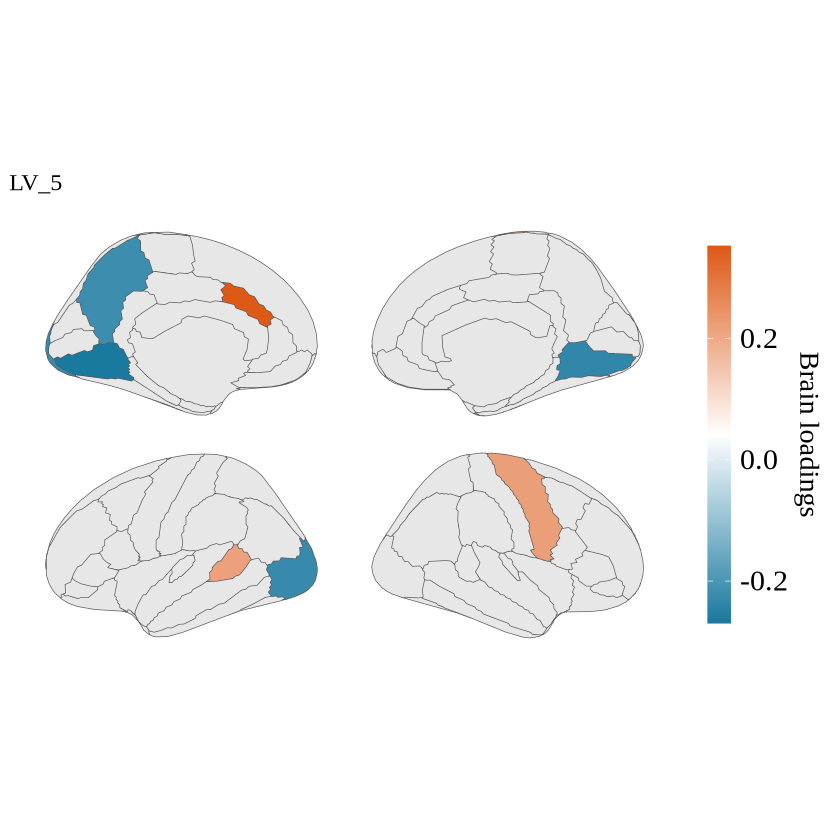

Merging atlas and data by label.


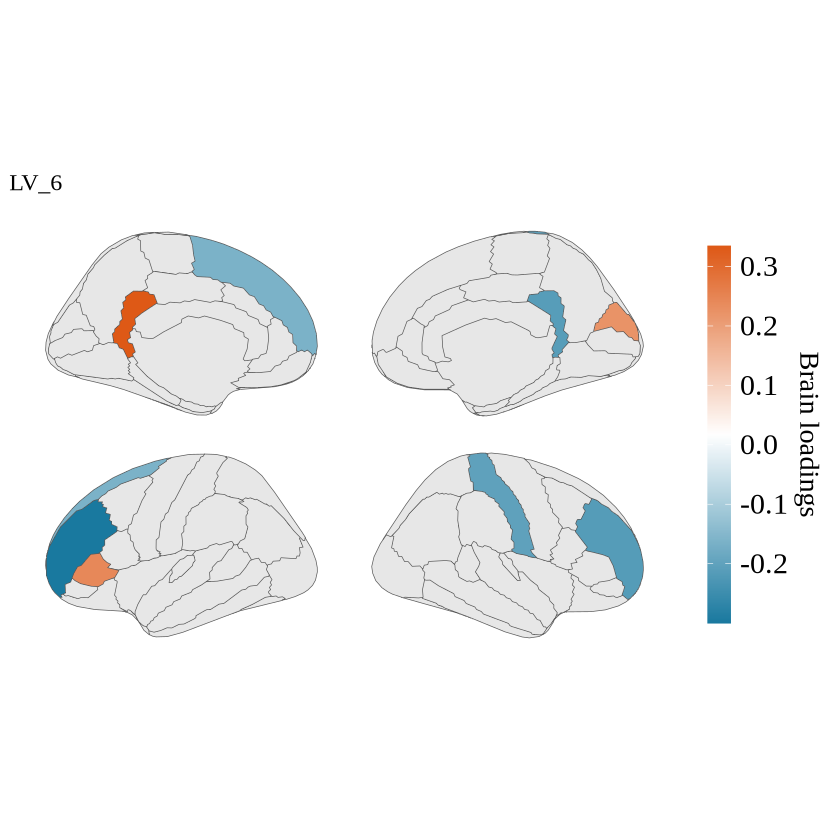

Merging atlas and data by label.


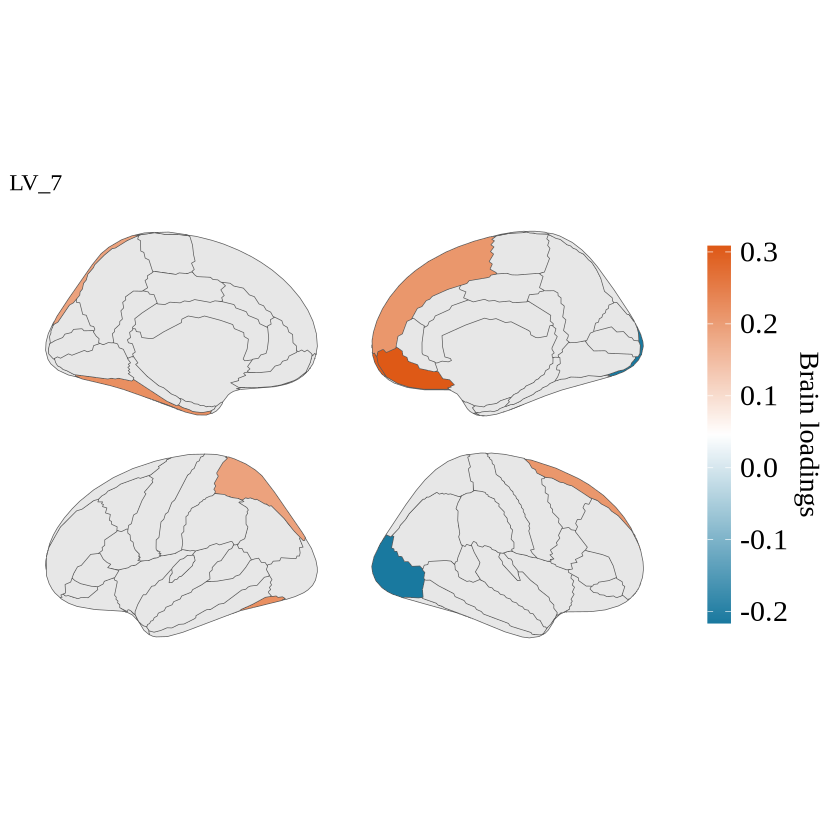

Merging atlas and data by label.


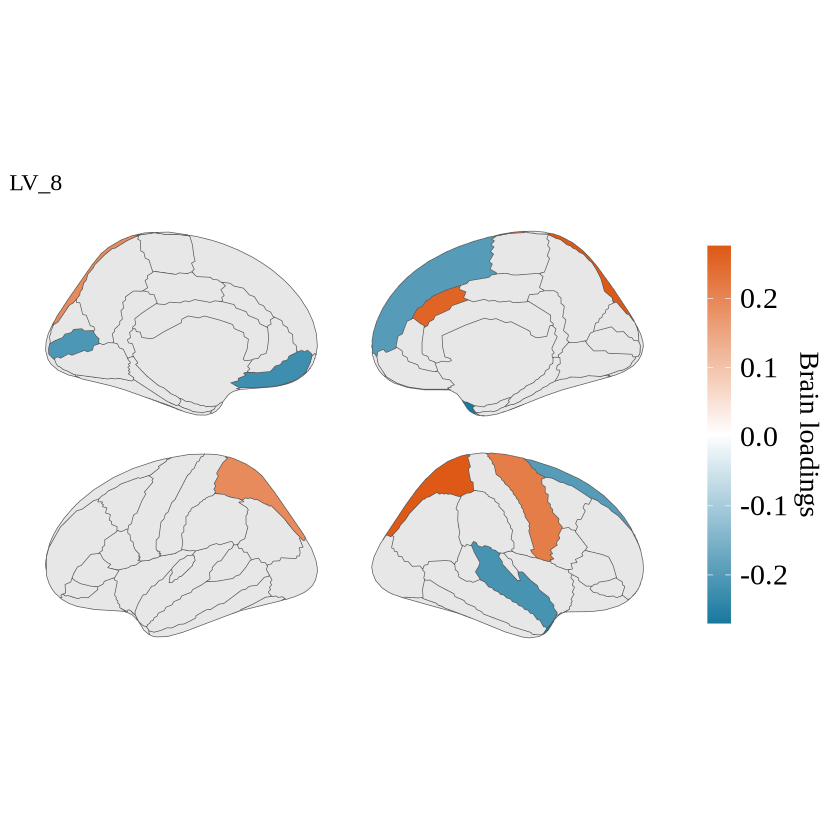

Merging atlas and data by label.


$LV_1

$LV_2

$LV_3

$LV_4

$LV_5

$LV_6

$LV_7

$LV_8

$LV_9

$LV_10


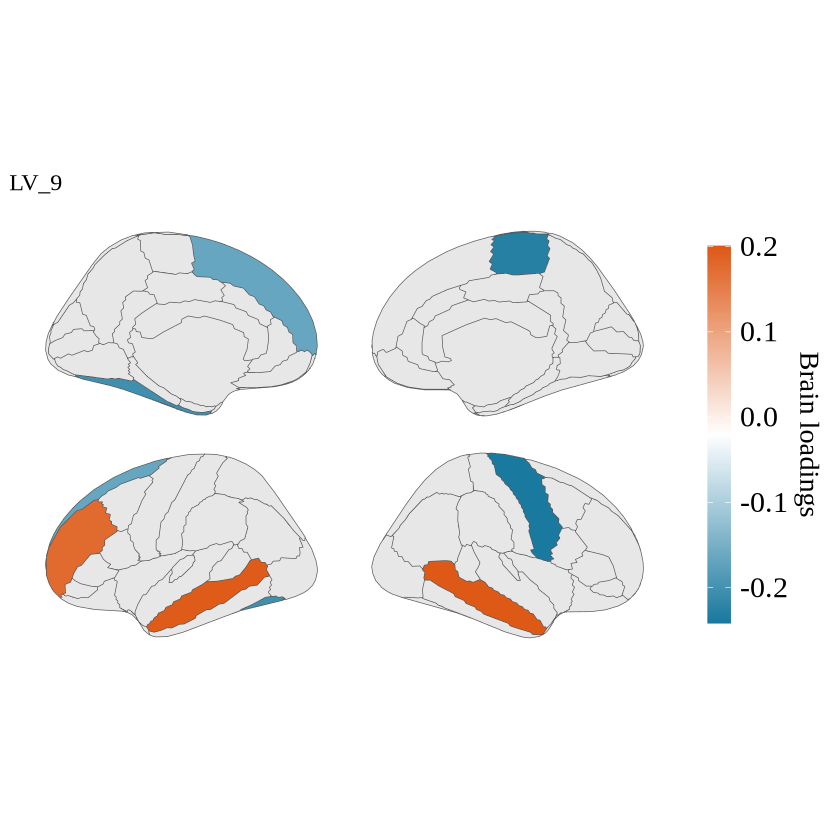

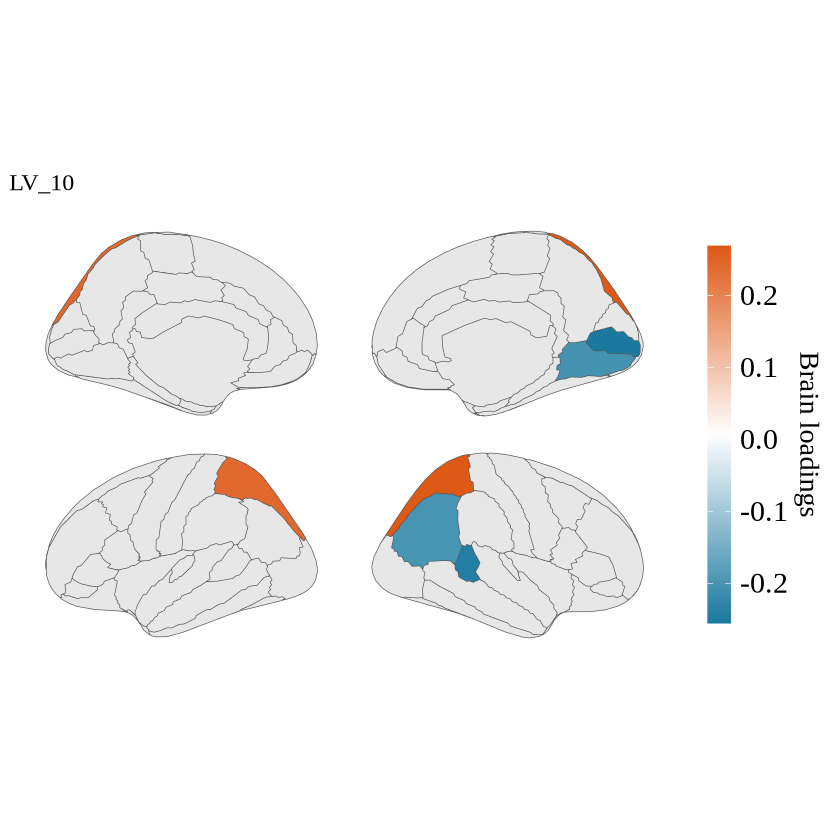

In [51]:
plot_MDTB_DK_Data4brain

## **4 Cerebellum plot**

In [52]:
dir.create("Statistics/PLS/",showWarnings = FALSE, recursive = TRUE)

MDTB_DK_LV_CI.u_filtered_val <- MDTB_DK_LV_CI.u %>% map(function(y)
                y %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>% drop_na()) %>% discard(~ nrow(.x) == 0)

In [53]:
MDTB_DK_LV_CI.u_filtered_val$LV_8 %>% as_tibble() %>%
                write_csv("Statistics/PLS/MDTB_DK_LV_CI_LV8.csv")

MDTB_DK_LV_CI.u_filtered_val$LV_9 %>% as_tibble() %>%
                write_csv("Statistics/PLS/MDTB_DK_LV_CI_LV9.csv")

MDTB_DK_LV_CI.u_filtered_val$LV_10 %>% as_tibble() %>%
                write_csv("Statistics/PLS/MDTB_DK_LV_CI_LV10.csv")

In [54]:
MDTB_DK_LV_CI.u_filtered <- MDTB_DK_LV_CI.u %>% map(function(y)
                y %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>% drop_na()) %>% discard(~ nrow(.x) == 0) %>% 
        names()

PLS_MDTB_rgb4Flatmap <- MDTB_DK_LV_CI.u_filtered %>%
        map(~
        read.table("Figures/Flatmap/MDTB/atl-MDTB10.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "Region", "Region ")) %>% rename("Region" = "V5")  %>%
        left_join(MDTB_DK_LV_CI.u[[.x]] %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>% 
                add_row(Region = "dummy", LV = -0.6) %>% add_row(Region = "dummy2", LV = 0.3) %>%
                mutate(hex_rgb = size_colors[cut(LV, breaks = 100)]) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(hex_rgb) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb)  %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame() ) %>%
            set_names(MDTB_DK_LV_CI.u_filtered)

Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`


In [55]:
dir.create("Figures/Flatmap/MDTB/flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(PLS_MDTB_rgb4Flatmap, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/MDTB/flatmap/", .y, "_PLS_MDTB_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

## **5 Group differences**

In [56]:
MDTB_DK_scores_PLS <- MDTB_DK_latentScores_list_PLS %>% 
    map(~  .x %>% 
    rename("DK_scores" = "V") %>% 
    rename("MDTB_scores" = "U") %>%
    add_column(merged_MDTB_DK_volumes %>% select(Substance,group)))

### **5.1 Users**

In [57]:
num_increase = 0.05
Cor_MDTB_DK_scores.user <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>%
    ggscatter(
        x = "DK_scores",
        y = "MDTB_scores",
        color = "Group",
        fill = "Group",
        palette = pal_user,
        add = "reg.line",
        size = 2,
        alpha = 0.3,
        xlab = "Brain Scores",
        ylab = "Cerebellar Scores",
        cor.coef = FALSE,
        conf.int = TRUE) +
    xlim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    ylim(.x$MDTB_scores %>% min() %>% round(0) - num_increase, 
        .x$MDTB_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(legend.position = "top") )

plot_DK_scores.user <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>% 
    ggplot(aes(x = Group, y = DK_scores, fill = Group)) + 
    geom_boxplot(width = .7) + 
    ylab("Brain Score LV1") +
    scale_color_manual(values = pal_user) +
    scale_fill_manual(values = pal_user) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1,
        size = 1.5, label.size = 10, vjust = 0.5
    ) + coord_flip() +
    ylim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) +
    theme(axis.line.x = element_blank(),
        axis.title.y = element_blank(),
        axis.line.y = element_blank(),
        axis.text.y = element_blank()) )

plot_MDTB_scores.user <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>% 
    ggplot(aes(x = Group, y = MDTB_scores, fill = Group)) + 
    geom_boxplot(width = .7) + 
    ylab("Behavior Score LV1") +
    scale_color_manual(values = pal_user) +
    scale_fill_manual(values = pal_user) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1,
        size = 1.5, label.size = 10, vjust = 0.5
    ) +
    ylim(.x$MDTB_scores %>% min() %>% round(0) - num_increase, 
        .x$MDTB_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) + 
    theme(axis.line.x = element_blank(),
        axis.line.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        axis.text.y = element_blank()) )

In [58]:
plot_MDTB_DK_scores.user <- Cor_MDTB_DK_scores.user %>% names() %>%
    map(~ 
        wrap_elements(plot_spacer() + (plot_DK_scores.user[[.x]]) + plot_spacer() +
            plot_layout(widths = c(0.3,1.5,0.5))) +
        wrap_elements((Cor_MDTB_DK_scores.user[[.x]] +
            theme(legend.position = "top") + plot_MDTB_scores.user[[.x]]) +
            plot_layout(widths = c(1.5,0.5),ncol = 2, nrow = 1)) + 
        plot_layout(ncol = 1, nrow = 2, heights = c(0.5,1.5))
         ) %>% 
    set_names(Cor_MDTB_DK_scores.user %>% names())

### **5.2 Substances**

In [59]:
num_increase = 0.05
Cor_MDTB_DK_scores.substances <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>%
    ggscatter(
        x = "DK_scores",
        y = "MDTB_scores",
        color = "Substance",
        fill = "Substance",
        palette = pal_substances,
        add = "reg.line",
        size = 2,
        alpha = 0.3,
        xlab = "Brain Scores",
        ylab = "Cerebellar Scores",
        cor.coef = FALSE,
        conf.int = TRUE) +
    xlim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    ylim(.x$MDTB_scores %>% min() %>% round(0) - num_increase, 
        .x$MDTB_scores %>% max() %>% round(0) + num_increase) +
    theme_ggdist() +
    theme_output +
    theme(legend.position = "top") )

plot_DK_scores.substances <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>% 
    ggplot(aes(x = Substance, y = DK_scores, fill = Substance)) + 
    geom_boxplot(width = .7) + 
    scale_color_manual(values = pal_substances) +
    scale_fill_manual(values = pal_substances) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1,
        step.increase = 0.2,
        size = 1.2, label.size = 10, vjust = 0.5
    ) + coord_flip() +
    ylim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) +
    theme(axis.line.x = element_blank(),
        axis.title.y = element_blank(),
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        legend.position = "none") )

plot_MDTB_scores.substances <- MDTB_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>% 
    ggplot(aes(x = Substance, y = MDTB_scores, fill = Substance)) + 
    geom_boxplot(width = .7) + 
    scale_color_manual(values = pal_substances) +
    scale_fill_manual(values = pal_substances) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1,
        step.increase = 0.2,
        size = 1.2, label.size = 10, vjust = 0.5
        
    ) +
    ylim(.x$MDTB_scores %>% min() %>% round(0) - num_increase, 
        .x$MDTB_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) + 
    theme(axis.line.x = element_blank(),
        axis.line.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        axis.text.y = element_blank(),
        legend.position = "none") )

In [60]:
plot_MDTB_DK_scores.substances <- Cor_MDTB_DK_scores.substances %>% names() %>%
    map(~ 
        wrap_elements(plot_spacer() + (plot_DK_scores.substances[[.x]]) + plot_spacer() +
            plot_layout(widths = c(0.3,1.5,0.5))) +
        wrap_elements((Cor_MDTB_DK_scores.substances[[.x]] +
            theme(legend.position = "none") + plot_MDTB_scores.substances[[.x]]) +
            plot_layout(widths = c(1.5,0.5),ncol = 2, nrow = 1)) + 
        plot_layout(ncol = 1, nrow = 2, heights = c(0.5,1.5))
         ) %>% 
    set_names(Cor_MDTB_DK_scores.substances %>% names())

## Export

In [61]:
if (!file.exists("Data/RData/MDTB_PLS_figures.RData")) {
    save(MDTB_DK_pval_singVal_list_filtered,
             MDTB_DK_LV_CI.u, MDTB_DK_PLS.v,
             plot_MDTB_DK_LV_CI.u_bar, plot_MDTB_DK_LV_CI.v_bar,
             plot_MDTB_DK_LV_CI.u_dot, plot_MDTB_DK_LV_CI.v_dot,
             plot_MDTB_DK_trainTest,
             MDTB_DK_Data4brain, plot_MDTB_DK_Data4brain,
             PLS_MDTB_rgb4Flatmap,
             MDTB_DK_scores_PLS, 
             Cor_MDTB_DK_scores.user, plot_DK_scores.user, plot_MDTB_scores.user,
             plot_MDTB_DK_scores.user,
             Cor_MDTB_DK_scores.substances, plot_DK_scores.substances, plot_MDTB_scores.substances,
             plot_MDTB_DK_scores.substances,
             MDTB_DK_PLS_variance, 
             MDTB_volumes_only_z_cor, 
             MDTB_DK_latentScores_list_PLS,
             MDTB_DK_PLS_svd_scaled,
             MDTB_DK_SingVecU_splitHalf, plot_MDTB_DK_SplitHalf_U,
             MDTB_DK_SingVecV_splitHalf, plot_MDTB_DK_SplitHalf_V,
             MDTB_DK_singVal_trainTest,
             file = "Data/RData/MDTB_PLS_figures.RData")
} else {
    message("Data/RData/MDTB_PLS_figures.RData already exists; skipping save.")
}

Data/RData/MDTB_PLS_figures.RData already exists; skipping save.



---
## **Sanity Check: PLS loading vector consistency (CC and AI datasets)**

Re-runs the SVD decomposition using complete-cases (CC) and alternative-imputed (AI) MDTB-DK data, then computes the absolute cosine similarity between the primary and sensitivity-analysis loading vectors for LV1–3.

A value near 1 indicates the MDTB-DK association pattern is robust to imputation choice.


In [62]:

if (!exists("Volumes_Cerebellum_MDTB_Harmonized_CC")) {
    load("Data/RData/Sanity_check/Volumes_Cerebellum_Sanity_check.RData")
}

# Run PLS SVD on CC and AI MDTB-DK datasets
run_pls_svd_mdtb <- function(mdtb_harmonized, dk_harmonized) {
    merged_df <- mdtb_harmonized %>%
        select(ID_MRI, Substance, contains("region")) %>%
        left_join(
            dk_harmonized %>% select(ID_MRI, Substance, contains("_")),
            by = c("ID_MRI", "Substance")
        ) %>%
        drop_na() %>%
        filter(!is.na(Substance), complete.cases(.))

    mdtb_z <- scale(merged_df %>% select(contains("region")))
    dk_z   <- scale(merged_df %>% select(contains("h_")))
    Rxy    <- cor(mdtb_z, dk_z, method = "spearman")
    svd(Rxy)
}

cos_sim_abs <- function(a, b) abs(as.numeric(a %*% b) / (sqrt(sum(a^2)) * sqrt(sum(b^2))))

pls_svd_MDTB_CC <- run_pls_svd_mdtb(Volumes_Cerebellum_MDTB_Harmonized_CC, Volumes_Cerebral_DK_Harmonized_CC)
pls_svd_MDTB_AI <- run_pls_svd_mdtb(Volumes_Cerebellum_MDTB_Harmonized_AI, Volumes_Cerebral_DK_Harmonized_AI)

n_lv_mdtb <- min(3, ncol(MDTB_DK_PLS_svd_scaled$u),
                 ncol(pls_svd_MDTB_CC$u), ncol(pls_svd_MDTB_AI$u))

pls_similarity_mdtb_dk <- map_dfr(1:n_lv_mdtb, function(lv) {
    tibble(
        LV               = lv,
        cos_U_primary_CC = cos_sim_abs(MDTB_DK_PLS_svd_scaled$u[, lv], pls_svd_MDTB_CC$u[, lv]),
        cos_V_primary_CC = cos_sim_abs(MDTB_DK_PLS_svd_scaled$v[, lv], pls_svd_MDTB_CC$v[, lv]),
        cos_U_primary_AI = cos_sim_abs(MDTB_DK_PLS_svd_scaled$u[, lv], pls_svd_MDTB_AI$u[, lv]),
        cos_V_primary_AI = cos_sim_abs(MDTB_DK_PLS_svd_scaled$v[, lv], pls_svd_MDTB_AI$v[, lv])
    )
})

dir.create("Statistics/Sanity_check/PLS", recursive = TRUE, showWarnings = FALSE)
write_csv(pls_similarity_mdtb_dk,
          "Statistics/Sanity_check/PLS/PLS_MDTB_DK_loading_similarity.csv")
print(pls_similarity_mdtb_dk)

save(pls_svd_MDTB_CC, pls_svd_MDTB_AI, pls_similarity_mdtb_dk,
     file = "Statistics/Sanity_check/PLS/PLS_MDTB_DK_sanity_check.RData")


# A tibble: 3 × 5
     LV cos_U_primary_CC cos_V_primary_CC cos_U_primary_AI cos_V_primary_AI
  <int>            <dbl>            <dbl>            <dbl>            <dbl>
1     1            1.000            1.000            1.000            1.000
2     2            0.999            0.978            1.000            0.997
3     3            0.996            0.982            1.000            0.997
